In [1]:
import scanpy as sc
import squidpy as sq

from pathlib import Path

from gctsvg import kidneycancer_preprocessing

In [2]:
data_dir = Path('data_repo/Human Kidney Cancer')

In [3]:
target_patient_id = 'PD47171'

In [4]:
adata_sc = sc.read(data_dir / 'RCC_upload_final_raw_counts.h5ad')

In [5]:
adata_sc

AnnData object with n_obs × n_vars = 270855 × 19736
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'patient', 'percent.mt', 'summaryDescription', 'annotation', 'region', 'broad_type'
    var: 'name'
    uns: 'annotation_colors', 'broad_type_colors', 'region_colors', 'summaryDescription_colors'
    obsm: 'X_pca', 'X_umap'

In [6]:
adata_sc.var[adata_sc.var.index.str.startswith("MT-")]

,name
MT-ND1,MT-ND1
MT-ND2,MT-ND2
MT-CO1,MT-CO1
MT-CO2,MT-CO2
MT-ATP8,MT-ATP8
MT-ATP6,MT-ATP6
MT-CO3,MT-CO3
MT-ND3,MT-ND3
MT-ND4L,MT-ND4L
MT-ND4,MT-ND4


In [7]:
adata_sc = kidneycancer_preprocessing.extract_sc_patient_data(adata_sc, target_patient_id)
adata_sc

AnnData object with n_obs × n_vars = 36110 × 19736
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'patient', 'percent.mt', 'summaryDescription', 'annotation', 'region', 'broad_type'
    var: 'name'
    uns: 'annotation_colors', 'broad_type_colors', 'region_colors', 'summaryDescription_colors'
    obsm: 'X_pca', 'X_umap'

In [8]:
adata_sc.obs

,orig.ident,nCount_RNA,nFeature_RNA,patient,percent.mt,summaryDescription,annotation,region,broad_type
5739STDY9266968_AACTGGTGTCTCCACT-1,5739STDY9266968,3598.0,1206,PD47171,7.254030,Tumour,Naïve_B.1,a,B-cell
5739STDY9266968_AGGGAGTGTCCGCTGA-1,5739STDY9266968,3447.0,1298,PD47171,5.686104,Tumour,Activated_B-RHOB,a,B-cell
5739STDY9266968_CATCGGGGTAAGGATT-1,5739STDY9266968,4602.0,601,PD47171,1.564537,Tumour,Plasma-IgA,a,Plasma
5739STDY9266968_CCACCTACAGCCTGTG-1,5739STDY9266968,3830.0,1854,PD47171,4.699739,Tumour,Naïve_B.1,a,B-cell
5739STDY9266968_CCACTACGTAGCGCAA-1,5739STDY9266968,3633.0,1427,PD47171,4.266446,Tumour,Activated_B-AREG,a,B-cell
...,...,...,...,...,...,...,...,...,...
5739STDY9266973_TTGTAGGTCCGCGTTT-1,5739STDY9266973,3627.0,1431,PD47171,11.524676,Tumour-normal,PT,g,RCC
5739STDY9266973_TTTATGCGTGTGACCC-1,5739STDY9266973,3598.0,1235,PD47171,15.953307,Tumour-normal,Stress,g,RCC
5739STDY9266973_TTTGGTTAGCGACGTA-1,5739STDY9266973,3809.0,1519,PD47171,10.028879,Tumour-normal,PT,g,RCC
5739STDY9266973_TTTGTCATCTATCCTA-1,5739STDY9266973,3901.0,1537,PD47171,5.229428,Tumour-normal,EMT,g,RCC


In [9]:
adata_sc.obs['broad_type'].unique()

['B-cell', 'Plasma', 'T-cell', 'NK', 'EC', ..., 'Epi_PT', 'Fibro', 'Myeloid', 'pDC', 'Mast']
Length: 12
Categories (12, object): ['B-cell', 'EC', 'Epi_non-PT', 'Epi_PT', ..., 'Plasma', 'RCC', 'T-cell', 'pDC']

In [10]:
adata_st_core = sc.read(data_dir / 'visium_merge_core_upload.h5ad')

In [11]:
adata_st_core.var[adata_st_core.var['SYMBOL'].str.startswith('mt-')]

,feature_types,genome,SYMBOL,mt,n_cells_by_counts-6800STDY12499406,mean_counts-6800STDY12499406,log1p_mean_counts-6800STDY12499406,pct_dropout_by_counts-6800STDY12499406,total_counts-6800STDY12499406,log1p_total_counts-6800STDY12499406,...,log1p_mean_counts-6800STDY12499508,pct_dropout_by_counts-6800STDY12499508,total_counts-6800STDY12499508,log1p_total_counts-6800STDY12499508,n_cells_by_counts-6800STDY12499509,mean_counts-6800STDY12499509,log1p_mean_counts-6800STDY12499509,pct_dropout_by_counts-6800STDY12499509,total_counts-6800STDY12499509,log1p_total_counts-6800STDY12499509
ENSEMBL,,,,,,,,,,,,,,,,,,,,,


In [12]:
adata_st_core.var[adata_st_core.var['SYMBOL'].str.startswith('MT')]

,feature_types,genome,SYMBOL,mt,n_cells_by_counts-6800STDY12499406,mean_counts-6800STDY12499406,log1p_mean_counts-6800STDY12499406,pct_dropout_by_counts-6800STDY12499406,total_counts-6800STDY12499406,log1p_total_counts-6800STDY12499406,...,log1p_mean_counts-6800STDY12499508,pct_dropout_by_counts-6800STDY12499508,total_counts-6800STDY12499508,log1p_total_counts-6800STDY12499508,n_cells_by_counts-6800STDY12499509,mean_counts-6800STDY12499509,log1p_mean_counts-6800STDY12499509,pct_dropout_by_counts-6800STDY12499509,total_counts-6800STDY12499509,log1p_total_counts-6800STDY12499509
ENSEMBL,,,,,,,,,,,,,,,,,,,,,
ENSG00000198793,Gene Expression,GRCh38,MTOR,False,94,0.030430,0.029976,97.195704,102.0,4.634729,...,0.035737,96.573649,103.0,4.644391,72,0.027037,0.026678,97.438634,76.0,4.343805
ENSG00000225602,Gene Expression,GRCh38,MTOR-AS1,False,0,0.000000,0.000000,100.000000,0.0,0.000000,...,0.000000,100.000000,0.0,0.000000,0,0.000000,0.000000,100.000000,0.0,0.000000
ENSG00000177000,Gene Expression,GRCh38,MTHFR,False,123,0.038783,0.038050,96.330549,130.0,4.875197,...,0.061974,93.959732,181.0,5.204007,129,0.049093,0.047926,95.410886,138.0,4.934474
ENSG00000117640,Gene Expression,GRCh38,MTFR1L,False,315,0.101432,0.096611,90.602625,340.0,5.831882,...,0.118764,88.873190,357.0,5.880533,202,0.081466,0.078317,92.813945,229.0,5.438079
ENSG00000188786,Gene Expression,GRCh38,MTF1,False,62,0.019690,0.019498,98.150358,66.0,4.204693,...,0.019588,98.127870,56.0,4.043051,64,0.023835,0.023555,97.723230,67.0,4.219508
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ENSG00000212907,Gene Expression,GRCh38,MT-ND4L,True,1783,1.283115,0.825541,46.807876,4301.0,8.366836,...,1.339564,18.756623,7976.0,8.984318,2173,2.910352,1.363627,22.696549,8181.0,9.009692
ENSG00000198886,Gene Expression,GRCh38,MT-ND4,True,3184,16.367243,2.854586,5.011933,54863.0,10.912613,...,3.615917,0.247262,102441.0,11.537052,2808,29.714693,3.424741,0.106724,83528.0,11.332949
ENSG00000198786,Gene Expression,GRCh38,MT-ND5,True,2493,2.954654,1.374893,25.626492,9904.0,9.200795,...,1.606750,10.632285,11286.0,9.331407,2385,3.440768,1.490827,15.154749,9672.0,9.177094


In [13]:
adata_st_core = kidneycancer_preprocessing.extract_st_patient_data(adata_st_core, target_patient_id)

['6800STDY12499410']
['spaceranger130_count_44214_6800STDY12499410_GRCh38-2020-A']


In [14]:
adata_st_core.var.columns.unique().tolist()

['feature_types',
 'genome',
 'SYMBOL',
 'mt',
 'n_cells_by_counts-6800STDY12499410',
 'mean_counts-6800STDY12499410',
 'log1p_mean_counts-6800STDY12499410',
 'pct_dropout_by_counts-6800STDY12499410',
 'total_counts-6800STDY12499410',
 'log1p_total_counts-6800STDY12499410']

In [15]:
adata_st_core.uns['spatial'].keys()

dict_keys(['spaceranger130_count_44214_6800STDY12499410_GRCh38-2020-A'])

In [16]:
adata_st_core

AnnData object with n_obs × n_vars = 3008 × 36601
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', 'donor_id', 'region'
    var: 'feature_types', 'genome', 'SYMBOL', 'mt', 'n_cells_by_counts-6800STDY12499410', 'mean_counts-6800STDY12499410', 'log1p_mean_counts-6800STDY12499410', 'pct_dropout_by_counts-6800STDY12499410', 'total_counts-6800STDY12499410', 'log1p_total_counts-6800STDY12499410'
    uns: 'sample_colors', 'spatial'
    obsm: 'spatial'

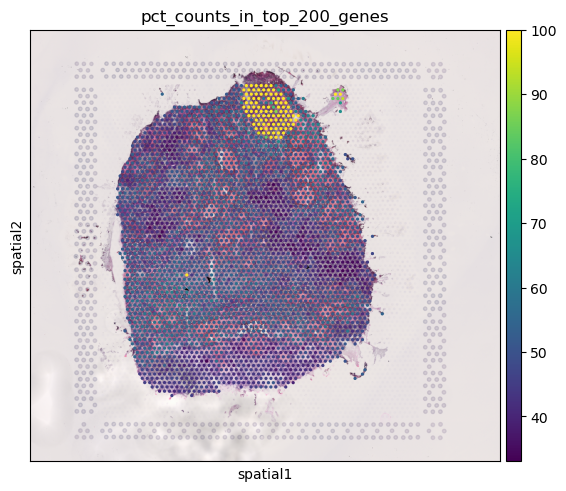

In [17]:
sq.pl.spatial_scatter(adata_st_core, color='pct_counts_in_top_200_genes')

In [18]:
adata_st_core.obsm['spatial'].shape

(3008, 2)

In [19]:
non_zero_locs = (adata_st_core.X > 0).sum(axis=0)
keep_genes = non_zero_locs >= 20
keep_genes.T.shape

(36601, 1)

In [20]:
type(adata_st_core.var['mt'])

pandas.core.series.Series

In [21]:
adata_st_core.var['mt'].shape

(36601,)

In [22]:
adata_st_core = kidneycancer_preprocessing.filter_st(adata_st_core)
adata_st_core

View of AnnData object with n_obs × n_vars = 2943 × 14837
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', 'donor_id', 'region'
    var: 'feature_types', 'genome', 'SYMBOL', 'mt', 'n_cells_by_counts-6800STDY12499410', 'mean_counts-6800STDY12499410', 'log1p_mean_counts-6800STDY12499410', 'pct_dropout_by_counts-6800STDY12499410', 'total_counts-6800STDY12499410', 'log1p_total_counts-6800STDY12499410'
    uns: 'sample_colors', 'spatial'
    obsm: 'spatial'

In [23]:
adata_st_inter = sc.read(data_dir / 'visium_merge_inter_upload.h5ad')

In [24]:
adata_st_inter = kidneycancer_preprocessing.extract_st_patient_data(adata_st_inter, target_patient_id)

['6800STDY12499411']
['spaceranger130_count_44214_6800STDY12499411_GRCh38-2020-A']


In [25]:
adata_st_inter.var.columns.unique().tolist()

['feature_types',
 'genome',
 'SYMBOL',
 'mt',
 'n_cells_by_counts-6800STDY12499411',
 'mean_counts-6800STDY12499411',
 'log1p_mean_counts-6800STDY12499411',
 'pct_dropout_by_counts-6800STDY12499411',
 'total_counts-6800STDY12499411',
 'log1p_total_counts-6800STDY12499411']

In [26]:
adata_st_inter.uns['spatial'].keys()

dict_keys(['spaceranger130_count_44214_6800STDY12499411_GRCh38-2020-A'])

In [27]:
adata_st_inter

AnnData object with n_obs × n_vars = 2048 × 36601
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', 'donor_id', 'region'
    var: 'feature_types', 'genome', 'SYMBOL', 'mt', 'n_cells_by_counts-6800STDY12499411', 'mean_counts-6800STDY12499411', 'log1p_mean_counts-6800STDY12499411', 'pct_dropout_by_counts-6800STDY12499411', 'total_counts-6800STDY12499411', 'log1p_total_counts-6800STDY12499411'
    uns: 'sample_colors', 'spatial'
    obsm: 'spatial'

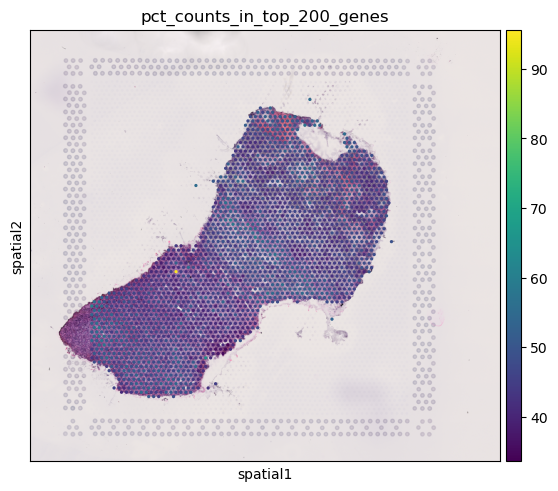

In [28]:
sq.pl.spatial_scatter(adata_st_inter, color='pct_counts_in_top_200_genes')

In [29]:
adata_st_inter.obsm['spatial'].shape

(2048, 2)

In [30]:
adata_st_inter = kidneycancer_preprocessing.filter_st(adata_st_inter)
adata_st_inter

View of AnnData object with n_obs × n_vars = 2048 × 15413
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', 'donor_id', 'region'
    var: 'feature_types', 'genome', 'SYMBOL', 'mt', 'n_cells_by_counts-6800STDY12499411', 'mean_counts-6800STDY12499411', 'log1p_mean_counts-6800STDY12499411', 'pct_dropout_by_counts-6800STDY12499411', 'total_counts-6800STDY12499411', 'log1p_total_counts-6800STDY12499411'
    uns: 'sample_colors', 'spatial'
    obsm: 'spatial'